In [ ]:
from google.colab import drive
import os
import tensorflow as tf

# Mount Google Drive
drive.mount("/content/drive")

# Permanent project locations
PROJECT_DIR = "/content/drive/MyDrive/DL-2 Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "saved_models")

# Create model storage folder if needed
os.makedirs(MODEL_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("Project folder exists:", os.path.isdir(PROJECT_DIR))
print("Model storage folder:", MODEL_DIR)
print("Model storage ready:", os.path.isdir(MODEL_DIR))

Mounted at /content/drive
TensorFlow version: 2.21.0
GPU available: True
Project folder exists: True
Model storage folder: /content/drive/MyDrive/DL-2 Project/saved_models
Model storage ready: True


In [11]:

import os
import sys
import subprocess

# Install KaggleHub if it isn't available in this runtime
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "kagglehub"
])

import kagglehub

print("Restoring the animal dataset...")

dataset_path = kagglehub.dataset_download(
    "mkstar1/animal-dataset-with-15-classes-of-animals"
)

DATASET_DIR = os.path.join(dataset_path, "Dataset")

print("\nDataset location:", DATASET_DIR)

for split in ["train", "validation", "test"]:
    split_path = os.path.join(DATASET_DIR, split)

    if os.path.isdir(split_path):
        classes = [
            name for name in os.listdir(split_path)
            if os.path.isdir(os.path.join(split_path, name))
        ]
        print(f"{split}: available, {len(classes)} classes")
    else:
        print(f"{split}: MISSING")

print("\nPersistent model folder:", MODEL_DIR)


Restoring the animal dataset...
Using Colab cache for faster access to the 'animal-dataset-with-15-classes-of-animals' dataset.

Dataset location: /kaggle/input/animal-dataset-with-15-classes-of-animals/Dataset
train: available, 15 classes
validation: available, 15 classes
test: available, 15 classes


NameError: name 'MODEL_DIR' is not defined

In [ ]:

import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(DATASET_DIR, "train")
val_dir = os.path.join(DATASET_DIR, "validation")
test_dir = os.path.join(DATASET_DIR, "test")

# Training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

class_names = train_ds.class_names

# Validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nNumber of classes:", len(class_names))
print("Class names:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("\nData pipelines ready!")

Found 7262 files belonging to 15 classes.
Found 923 files belonging to 15 classes.
Found 899 files belonging to 15 classes.

Number of classes: 15
Class names: ['Armadilles', 'Bear', 'Birds', 'Cow', 'Crocodile', 'Deer', 'Elephant', 'Goat', 'Horse', 'Jaguar', 'Monkey', 'Rabbit', 'Skunk', 'Tiger', 'Wild Boar']
Training batches: 227
Validation batches: 29
Test batches: 29

Data pipelines ready!


In [ ]:

import os
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

mobilenet_checkpoint = os.path.join(
    MODEL_DIR, "mobilenetv2_best.keras"
)

# Load ImageNet-pretrained feature extractor
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

# Build the 15-class classifier
inputs = keras.Input(shape=(224, 224, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

mobilenet_model = keras.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        mobilenet_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint will be saved to:", mobilenet_checkpoint)

start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

mobilenet_training_seconds = time.time() - start_time

print(f"\nTraining time: {mobilenet_training_seconds / 60:.2f} minutes")
print("Checkpoint exists:", os.path.isfile(mobilenet_checkpoint))

if os.path.isfile(mobilenet_checkpoint):
    print(
        "Checkpoint size:",
        round(os.path.getsize(mobilenet_checkpoint) / (1024 * 1024), 2),
        "MB"
    )

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Checkpoint will be saved to: /content/drive/MyDrive/DL-2 Project/saved_models/mobilenetv2_best.keras
Epoch 1/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.7272 - loss: 0.9774
Epoch 1: val_accuracy improved from None to 0.96316, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/mobilenetv2_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 46s 150ms/step - accuracy: 0.8704 - loss: 0.4760 - val_accuracy: 0.9632 - val_loss: 0.1408 - learning_rate: 0.0010
Epoch 2/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9625 - loss: 0.1360
Epoch 2: val_accuracy improved from 0.96316 to 0.96641, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/mobilenetv2_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 21s

In [ ]:

import os
import json
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load the persistent checkpoint from Google Drive
best_mobilenet = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "mobilenetv2_best.keras")
)

# Get true labels and predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

probabilities = best_mobilenet.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Calculate test metrics
metrics = {
    "Model": "MobileNetV2",
    "Test Accuracy": float(accuracy_score(y_true, y_pred)),
    "Macro Precision": float(precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )),
    "Macro Recall": float(recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )),
    "Macro F1": float(f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )),
    "Training Time (min)": round(
        mobilenet_training_seconds / 60, 2
    )
}

print("\n--- MOBILENETV2 TEST RESULTS ---")
for key, value in metrics.items():
    if isinstance(value, float) and key != "Training Time (min)":
        print(f"{key}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{key}: {value}")

print("\n--- PER-CLASS REPORT ---")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Save the measured metrics to Drive
metrics_path = os.path.join(
    PROJECT_DIR, "mobilenetv2_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("\nMetrics saved to:", metrics_path)

29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 236ms/step

--- MOBILENETV2 TEST RESULTS ---
Model: MobileNetV2
Test Accuracy: 0.9622 (96.22%)
Macro Precision: 0.9651 (96.51%)
Macro Recall: 0.9675 (96.75%)
Macro F1: 0.9659 (96.59%)
Training Time (min): 2.13

--- PER-CLASS REPORT ---
              precision    recall  f1-score   support

  Armadilles     0.9825    0.9492    0.9655       118
        Bear     1.0000    0.9608    0.9800        51
       Birds     0.9583    1.0000    0.9787        23
         Cow     0.9286    1.0000    0.9630        39
   Crocodile     1.0000    0.9600    0.9796        25
        Deer     0.9701    0.9028    0.9353        72
    Elephant     0.9868    0.9494    0.9677        79
        Goat     0.9333    0.9655    0.9492        29
       Horse     0.9182    0.9619    0.9395       105
      Jaguar     1.0000    1.0000    1.0000        88
      Monkey     1.0000    1.0000    1.0000        28
      Rabbit     0.9136    0.9610    0.9367        77
       Skunk     0.9839    0.9

In [ ]:

import os
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

resnet_checkpoint = os.path.join(
    MODEL_DIR, "resnet50_best.keras"
)

# Load ImageNet-pretrained ResNet50
resnet_base = keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
resnet_base.trainable = False

# Build the 15-class classifier
inputs = keras.Input(shape=(224, 224, 3))

x = keras.applications.resnet50.preprocess_input(inputs)
x = resnet_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

resnet_model = keras.Model(inputs, outputs)

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        resnet_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint destination:", resnet_checkpoint)

start_time = time.time()

resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

resnet_training_seconds = time.time() - start_time

print(f"\nTraining time: {resnet_training_seconds / 60:.2f} minutes")
print("Checkpoint exists:", os.path.isfile(resnet_checkpoint))

if os.path.isfile(resnet_checkpoint):
    print(
        "Checkpoint size:",
        round(os.path.getsize(resnet_checkpoint) / (1024 * 1024), 2),
        "MB"
    )

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Checkpoint destination: /content/drive/MyDrive/DL-2 Project/saved_models/resnet50_best.keras
Epoch 1/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.7223 - loss: 0.9499
Epoch 1: val_accuracy improved from None to 0.94150, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/resnet50_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/resnet50_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 54s 182ms/step - accuracy: 0.8696 - loss: 0.4442 - val_accuracy: 0.9415 - val_loss: 0.1508 - learning_rate: 0.0010
Epoch 2/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.9645 - loss: 0.1177
Epoch 2: val_accuracy improved from 0.94150 to 0.97075, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/resnet50_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/resnet50_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 29s 126ms/step - accu

In [7]:

import os
import json
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load the best ResNet50 checkpoint from Drive
best_resnet = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "resnet50_best.keras")
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

resnet_probabilities = best_resnet.predict(test_ds, verbose=1)
resnet_predictions = np.argmax(resnet_probabilities, axis=1)

resnet_metrics = {
    "Model": "ResNet50",
    "Test Accuracy": float(
        accuracy_score(y_true, resnet_predictions)
    ),
    "Macro Precision": float(
        precision_score(
            y_true, resnet_predictions,
            average="macro", zero_division=0
        )
    ),
    "Macro Recall": float(
        recall_score(
            y_true, resnet_predictions,
            average="macro", zero_division=0
        )
    ),
    "Macro F1": float(
        f1_score(
            y_true, resnet_predictions,
            average="macro", zero_division=0
        )
    ),
    "Training Time (min)": round(
        resnet_training_seconds / 60, 2
    )
}

print("\n--- RESNET50 TEST RESULTS ---")
for key, value in resnet_metrics.items():
    if isinstance(value, float) and key != "Training Time (min)":
        print(f"{key}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{key}: {value}")

print("\n--- PER-CLASS REPORT ---")
print(classification_report(
    y_true,
    resnet_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Save metrics persistently in Drive
metrics_path = os.path.join(
    PROJECT_DIR, "resnet50_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(resnet_metrics, f, indent=2)

print("\nMetrics saved to:", metrics_path)


29/29 ━━━━━━━━━━━━━━━━━━━━ 11s 268ms/step

--- RESNET50 TEST RESULTS ---
Model: ResNet50
Test Accuracy: 0.9611 (96.11%)
Macro Precision: 0.9617 (96.17%)
Macro Recall: 0.9609 (96.09%)
Macro F1: 0.9610 (96.10%)
Training Time (min): 5.19

--- PER-CLASS REPORT ---
              precision    recall  f1-score   support

  Armadilles     0.9829    0.9746    0.9787       118
        Bear     0.9592    0.9216    0.9400        51
       Birds     1.0000    1.0000    1.0000        23
         Cow     0.9286    1.0000    0.9630        39
   Crocodile     1.0000    1.0000    1.0000        25
        Deer     0.9452    0.9583    0.9517        72
    Elephant     0.9383    0.9620    0.9500        79
        Goat     0.8929    0.8621    0.8772        29
       Horse     0.9352    0.9619    0.9484       105
      Jaguar     1.0000    1.0000    1.0000        88
      Monkey     1.0000    1.0000    1.0000        28
      Rabbit     0.9615    0.9740    0.9677        77
       Skunk     1.0000    0.9375   

In [8]:

import os
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

efficient_checkpoint = os.path.join(
    MODEL_DIR, "efficientnetb0_best.keras"
)

# Load pretrained EfficientNetB0
efficient_base = keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
efficient_base.trainable = False

# Build classifier
inputs = keras.Input(shape=(224, 224, 3))

# EfficientNetB0 includes input rescaling internally
x = efficient_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

efficient_model = keras.Model(inputs, outputs)

efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        efficient_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint destination:", efficient_checkpoint)

start_time = time.time()

efficient_history = efficient_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

efficient_training_seconds = time.time() - start_time

print(
    f"\nTraining time: {efficient_training_seconds / 60:.2f} minutes"
)
print("Checkpoint exists:", os.path.isfile(efficient_checkpoint))

if os.path.isfile(efficient_checkpoint):
    print(
        "Checkpoint size:",
        round(os.path.getsize(efficient_checkpoint) / (1024 * 1024), 2),
        "MB"
    )


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Checkpoint destination: /content/drive/MyDrive/DL-2 Project/saved_models/efficientnetb0_best.keras
Epoch 1/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.7628 - loss: 1.0276
Epoch 1: val_accuracy improved from None to 0.97183, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/efficientnetb0_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 71s 207ms/step - accuracy: 0.9013 - loss: 0.4960 - val_accuracy: 0.9718 - val_loss: 0.1297 - learning_rate: 0.0010
Epoch 2/10
226/227 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9744 - loss: 0.1231
Epoch 2: val_accuracy improved from 0.97183 to 0.97508, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/efficientnetb0_best.keras
227/227 ━━━━━━━━━━━━

In [9]:

import os
import json
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load best checkpoint from persistent Drive storage
best_efficient = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "efficientnetb0_best.keras")
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

efficient_probabilities = best_efficient.predict(
    test_ds, verbose=1
)
efficient_predictions = np.argmax(
    efficient_probabilities, axis=1
)

efficient_metrics = {
    "Model": "EfficientNetB0",
    "Test Accuracy": float(
        accuracy_score(y_true, efficient_predictions)
    ),
    "Macro Precision": float(
        precision_score(
            y_true, efficient_predictions,
            average="macro", zero_division=0
        )
    ),
    "Macro Recall": float(
        recall_score(
            y_true, efficient_predictions,
            average="macro", zero_division=0
        )
    ),
    "Macro F1": float(
        f1_score(
            y_true, efficient_predictions,
            average="macro", zero_division=0
        )
    ),
    "Training Time (min)": round(
        efficient_training_seconds / 60, 2
    )
}

print("\n--- EFFICIENTNETB0 TEST RESULTS ---")
for key, value in efficient_metrics.items():
    if isinstance(value, float) and key != "Training Time (min)":
        print(f"{key}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{key}: {value}")

print("\n--- PER-CLASS REPORT ---")
print(classification_report(
    y_true,
    efficient_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

metrics_path = os.path.join(
    PROJECT_DIR, "efficientnetb0_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(efficient_metrics, f, indent=2)

print("\nMetrics saved to:", metrics_path)

29/29 ━━━━━━━━━━━━━━━━━━━━ 17s 398ms/step

--- EFFICIENTNETB0 TEST RESULTS ---
Model: EfficientNetB0
Test Accuracy: 0.9755 (97.55%)
Macro Precision: 0.9755 (97.55%)
Macro Recall: 0.9804 (98.04%)
Macro F1: 0.9777 (97.77%)
Training Time (min): 4.27

--- PER-CLASS REPORT ---
              precision    recall  f1-score   support

  Armadilles     0.9915    0.9831    0.9872       118
        Bear     1.0000    0.9804    0.9901        51
       Birds     0.9583    1.0000    0.9787        23
         Cow     1.0000    1.0000    1.0000        39
   Crocodile     1.0000    1.0000    1.0000        25
        Deer     0.9722    0.9722    0.9722        72
    Elephant     0.9744    0.9620    0.9682        79
        Goat     0.9062    1.0000    0.9508        29
       Horse     0.9528    0.9619    0.9573       105
      Jaguar     1.0000    1.0000    1.0000        88
      Monkey     1.0000    1.0000    1.0000        28
      Rabbit     0.9610    0.9610    0.9610        77
       Skunk     0.9836 

In [10]:

import os
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

dense_checkpoint = os.path.join(
    MODEL_DIR, "densenet121_best.keras"
)

# Load ImageNet-pretrained DenseNet121
dense_base = keras.applications.DenseNet121(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
dense_base.trainable = False

# Build classifier for 15 animal classes
inputs = keras.Input(shape=(224, 224, 3))

x = keras.applications.densenet.preprocess_input(inputs)
x = dense_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

dense_model = keras.Model(inputs, outputs)

dense_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        dense_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint destination:", dense_checkpoint)

start_time = time.time()

dense_history = dense_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

dense_training_seconds = time.time() - start_time

print(
    f"\nTraining time: {dense_training_seconds / 60:.2f} minutes"
)
print("Checkpoint exists:", os.path.isfile(dense_checkpoint))

if os.path.isfile(dense_checkpoint):
    print(
        "Checkpoint size:",
        round(os.path.getsize(dense_checkpoint) / (1024 * 1024), 2),
        "MB"
    )


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Checkpoint destination: /content/drive/MyDrive/DL-2 Project/saved_models/densenet121_best.keras
Epoch 1/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.5552 - loss: 1.5780
Epoch 1: val_accuracy improved from None to 0.95775, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/densenet121_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/densenet121_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 92s 288ms/step - accuracy: 0.7765 - loss: 0.8060 - val_accuracy: 0.9577 - val_loss: 0.1894 - learning_rate: 0.0010
Epoch 2/10
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.9402 - loss: 0.2226
Epoch 2: val_accuracy improved from 0.95775 to 0.97291, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/densenet121_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/densenet121_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 26s 11

In [11]:

import os
import json
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tensorflow import keras

# Load the best saved DenseNet121 checkpoint
dense_model = keras.models.load_model(
    os.path.join(MODEL_DIR, "densenet121_best.keras")
)

# Get predictions on the test dataset
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_probs = dense_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_probs, axis=1)

# Calculate evaluation metrics
dense_metrics = {
    "model": "DenseNet121",
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(
        precision_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "macro_recall": float(
        recall_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "training_time_minutes": round(dense_training_seconds / 60, 2),
    "model_size_mb": round(
        os.path.getsize(
            os.path.join(MODEL_DIR, "densenet121_best.keras")
        ) / (1024 * 1024), 2
    )
}

# Display metrics
for metric, value in dense_metrics.items():
    print(f"{metric}: {value}")

# Save metrics permanently to Google Drive
metrics_path = os.path.join(PROJECT_DIR, "densenet121_metrics.json")
with open(metrics_path, "w") as f:
    json.dump(dense_metrics, f, indent=4)

print("\nMetrics saved to:", metrics_path)

29/29 ━━━━━━━━━━━━━━━━━━━━ 29s 607ms/step
model: DenseNet121
accuracy: 0.9733036707452726
macro_precision: 0.97444829665349
macro_recall: 0.9757141883102298
macro_f1: 0.9749019563962572
training_time_minutes: 3.82
model_size_mb: 28.47

Metrics saved to: /content/drive/MyDrive/DL-2 Project/densenet121_metrics.json


In [12]:

import os
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Save the best model directly to Google Drive
cnn_checkpoint = os.path.join(
    MODEL_DIR, "custom_cnn_best.keras"
)

# Data augmentation to help the model generalize
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="data_augmentation")

# Build the CNN from scratch
inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)

# Convolution block 1
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)

# Convolution block 2
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)

# Convolution block 3
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names), activation="softmax"
)(x)

custom_cnn = keras.Model(inputs, outputs, name="Custom_CNN")

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()
print("\nCheckpoint destination:", cnn_checkpoint)

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,695 (436.31 KB)

 Trainable params: 111,695 (436.31 KB)

 Non-trainable params: 0 (0.00 B)


Checkpoint destination: /content/drive/MyDrive/DL-2 Project/saved_models/custom_cnn_best.keras


In [13]:

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

cnn_callbacks = [
    ModelCheckpoint(
        cnn_checkpoint,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

start_time = time.time()

cnn_history = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=cnn_callbacks
)

cnn_training_seconds = time.time() - start_time

print(f"\nTraining time: {cnn_training_seconds / 60:.2f} minutes")
print("Checkpoint exists:", os.path.isfile(cnn_checkpoint))

if os.path.isfile(cnn_checkpoint):
    print(
        "Checkpoint size:",
        round(os.path.getsize(cnn_checkpoint) / (1024 * 1024), 2),
        "MB"
    )


Epoch 1/20
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.1180 - loss: 2.6204
Epoch 1: val_accuracy improved from None to 0.15276, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/custom_cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/custom_cnn_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 36s 97ms/step - accuracy: 0.1418 - loss: 2.5827 - val_accuracy: 0.1528 - val_loss: 2.5171 - learning_rate: 0.0010
Epoch 2/20
226/227 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.1824 - loss: 2.4708
Epoch 2: val_accuracy improved from 0.15276 to 0.20693, saving model to /content/drive/MyDrive/DL-2 Project/saved_models/custom_cnn_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DL-2 Project/saved_models/custom_cnn_best.keras
227/227 ━━━━━━━━━━━━━━━━━━━━ 28s 91ms/step - accuracy: 0.1990 - loss: 2.4408 - val_accuracy: 0.2069 - val_loss: 2.3202 - learning_rate: 0.0010
Epoch 3/20
226/227 ━━━━━━━━━━━━━━━━━━━━ 0s 81

In [14]:

import os
import json
import numpy as np
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load the best saved checkpoint
custom_cnn = keras.models.load_model(cnn_checkpoint)

# Collect true labels and predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_probs = custom_cnn.predict(test_ds, verbose=1)
y_pred = np.argmax(y_probs, axis=1)

# Calculate test metrics
cnn_metrics = {
    "model": "Custom CNN",
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(
        precision_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "macro_recall": float(
        recall_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "training_time_minutes": round(cnn_training_seconds / 60, 2),
    "model_size_mb": round(
        os.path.getsize(cnn_checkpoint) / (1024 * 1024), 2
    )
}

for metric, value in cnn_metrics.items():
    print(f"{metric}: {value}")

# Save metrics to Google Drive
metrics_path = os.path.join(PROJECT_DIR, "custom_cnn_metrics.json")

with open(metrics_path, "w") as f:
    json.dump(cnn_metrics, f, indent=4)

print("\nMetrics saved to:", metrics_path)


29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step
model: Custom CNN
accuracy: 0.3604004449388209
macro_precision: 0.31719797563468255
macro_recall: 0.26291334082328083
macro_f1: 0.23974472074042624
training_time_minutes: 7.65
model_size_mb: 1.34

Metrics saved to: /content/drive/MyDrive/DL-2 Project/custom_cnn_metrics.json


29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 320ms/step


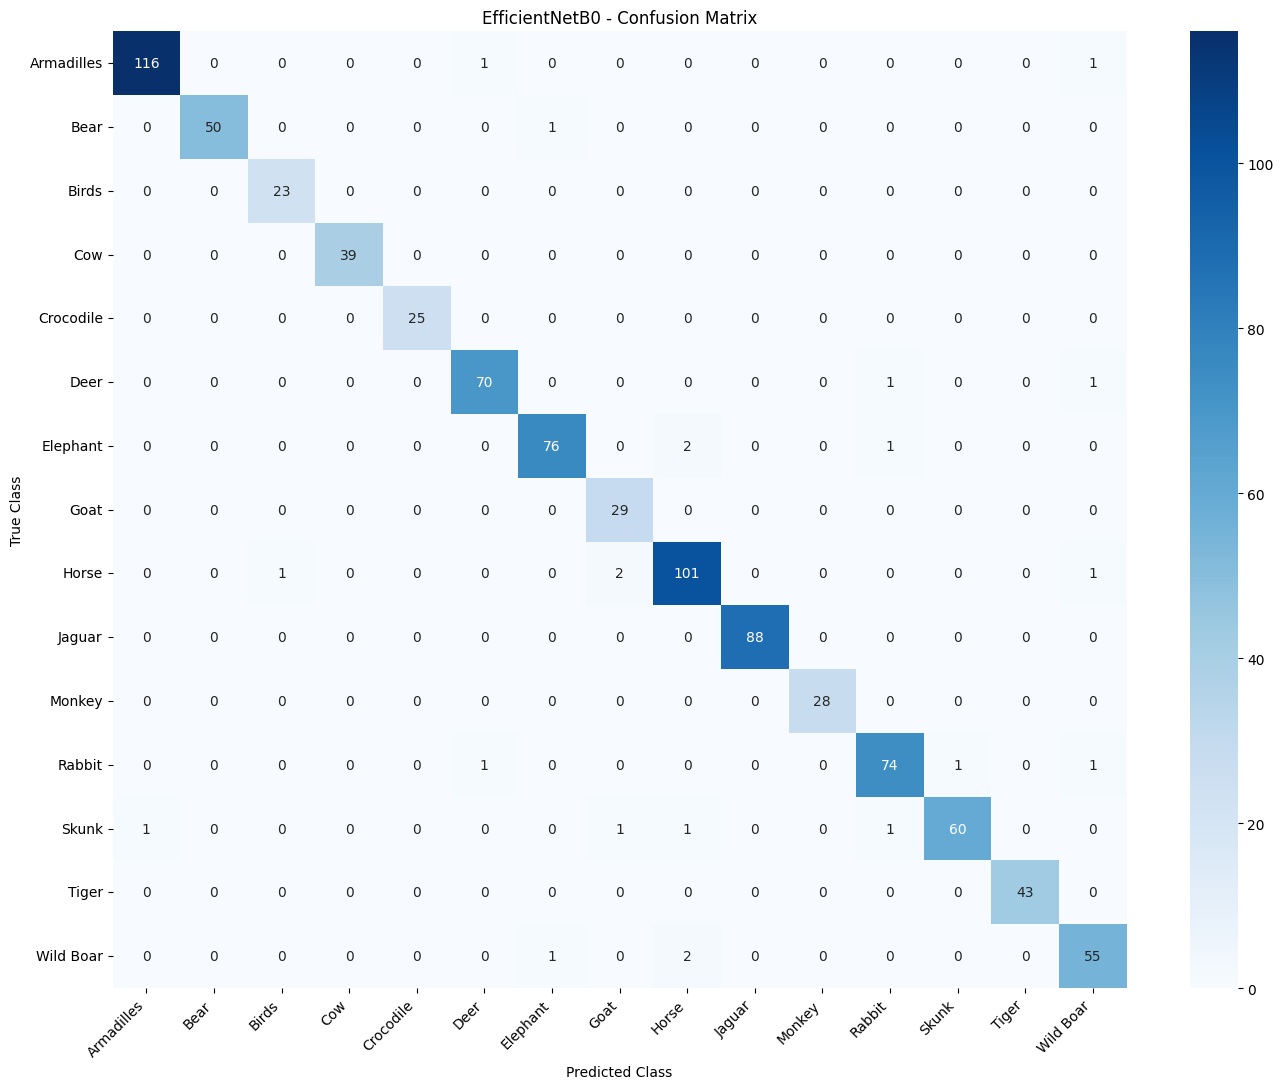

Confusion matrix saved to: /content/drive/MyDrive/DL-2 Project/efficientnetb0_confusion_matrix.png

Classification Report:

              precision    recall  f1-score   support

  Armadilles     0.9915    0.9831    0.9872       118
        Bear     1.0000    0.9804    0.9901        51
       Birds     0.9583    1.0000    0.9787        23
         Cow     1.0000    1.0000    1.0000        39
   Crocodile     1.0000    1.0000    1.0000        25
        Deer     0.9722    0.9722    0.9722        72
    Elephant     0.9744    0.9620    0.9682        79
        Goat     0.9062    1.0000    0.9508        29
       Horse     0.9528    0.9619    0.9573       105
      Jaguar     1.0000    1.0000    1.0000        88
      Monkey     1.0000    1.0000    1.0000        28
      Rabbit     0.9610    0.9610    0.9610        77
       Skunk     0.9836    0.9375    0.9600        64
       Tiger     1.0000    1.0000    1.0000        43
   Wild Boar     0.9322    0.9483    0.9402        58

    accura

In [15]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import confusion_matrix, classification_report

# Load the saved best EfficientNetB0 model
efficientnet_checkpoint = os.path.join(
    MODEL_DIR, "efficientnetb0_best.keras"
)

efficientnet_model = keras.models.load_model(
    efficientnet_checkpoint
)

# Get actual labels and model predictions
y_true_eff = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_probs_eff = efficientnet_model.predict(test_ds, verbose=1)
y_pred_eff = np.argmax(y_probs_eff, axis=1)

# Create confusion matrix
cm = confusion_matrix(
    y_true_eff,
    y_pred_eff,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(14, 11))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the figure to Google Drive
confusion_path = os.path.join(
    PROJECT_DIR, "efficientnetb0_confusion_matrix.png"
)

plt.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", confusion_path)

# Per-class precision, recall and F1-score
print("\nClassification Report:\n")
print(classification_report(
    y_true_eff,
    y_pred_eff,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))


In [17]:

import os
import json

model_files = {
    "MobileNetV2": "mobilenetv2_metrics.json",
    "ResNet50": "resnet50_metrics.json",
    "EfficientNetB0": "efficientnetb0_metrics.json",
    "DenseNet121": "densenet121_metrics.json",
    "Custom CNN": "custom_cnn_metrics.json"
}

for model_name, filename in model_files.items():
    path = os.path.join(PROJECT_DIR, filename)

    with open(path, "r") as f:
        data = json.load(f)

    print(f"\n--- {model_name} ---")
    print(json.dumps(data, indent=2))



--- MobileNetV2 ---
{
  "Model": "MobileNetV2",
  "Test Accuracy": 0.9621802002224694,
  "Macro Precision": 0.9651305314455402,
  "Macro Recall": 0.9674629032583829,
  "Macro F1": 0.9658539454922493,
  "Training Time (min)": 2.13
}

--- ResNet50 ---
{
  "Model": "ResNet50",
  "Test Accuracy": 0.9610678531701891,
  "Macro Precision": 0.9616800293599598,
  "Macro Recall": 0.960938147692778,
  "Macro F1": 0.9609716024143203,
  "Training Time (min)": 5.19
}

--- EfficientNetB0 ---
{
  "Model": "EfficientNetB0",
  "Test Accuracy": 0.9755283648498332,
  "Macro Precision": 0.9754864412195523,
  "Macro Recall": 0.9804273418673987,
  "Macro F1": 0.9777204726719193,
  "Training Time (min)": 4.27
}

--- DenseNet121 ---
{
  "model": "DenseNet121",
  "accuracy": 0.9733036707452726,
  "macro_precision": 0.97444829665349,
  "macro_recall": 0.9757141883102298,
  "macro_f1": 0.9749019563962572,
  "training_time_minutes": 3.82,
  "model_size_mb": 28.47
}

--- Custom CNN ---
{
  "model": "Custom CNN",
 

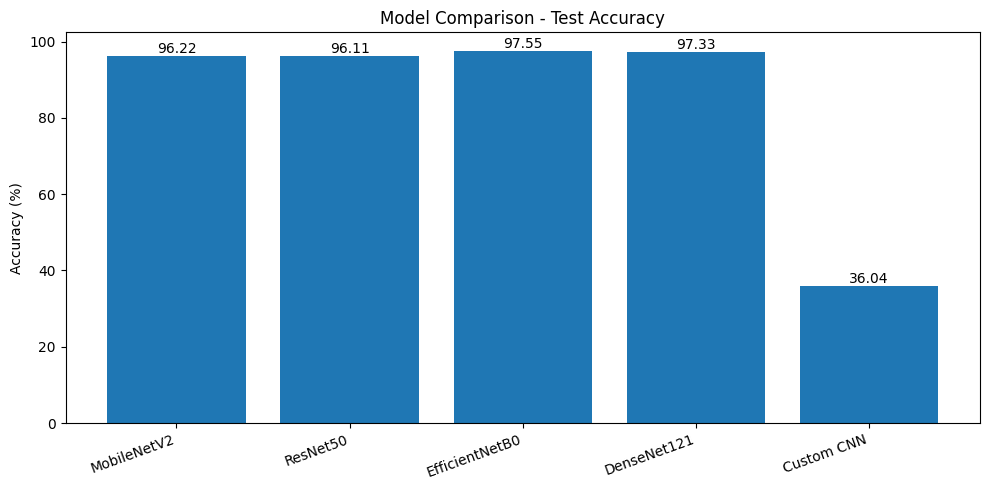

Saved: /content/drive/MyDrive/DL-2 Project/comparison_charts/accuracy_comparison.png


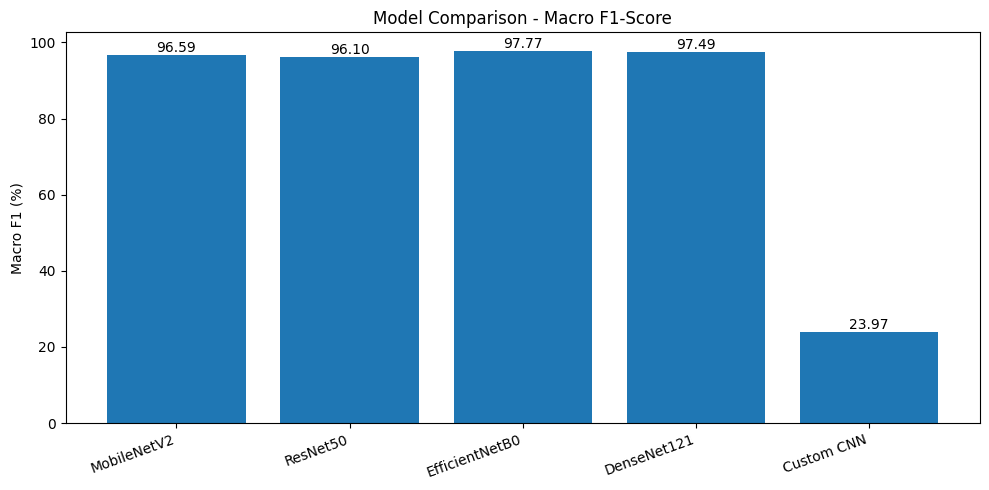

Saved: /content/drive/MyDrive/DL-2 Project/comparison_charts/macro_f1_comparison.png


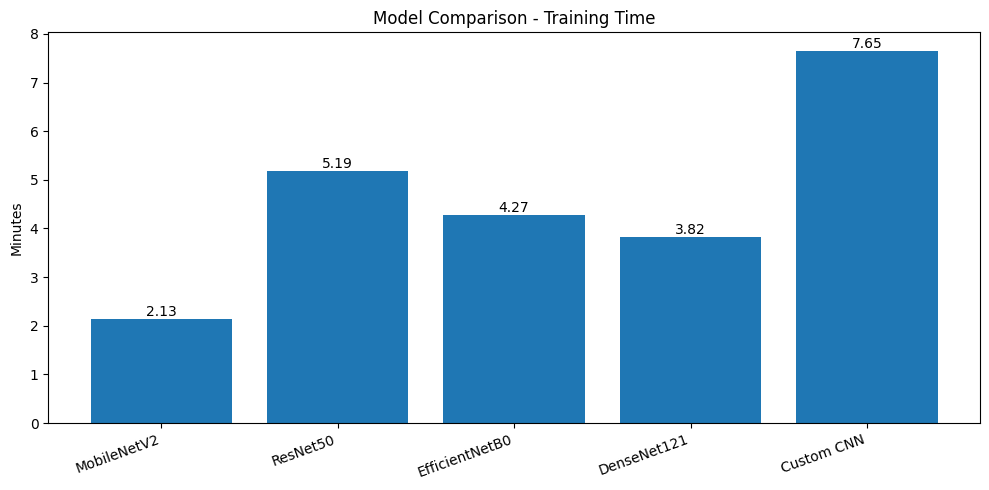

Saved: /content/drive/MyDrive/DL-2 Project/comparison_charts/training_time_comparison.png


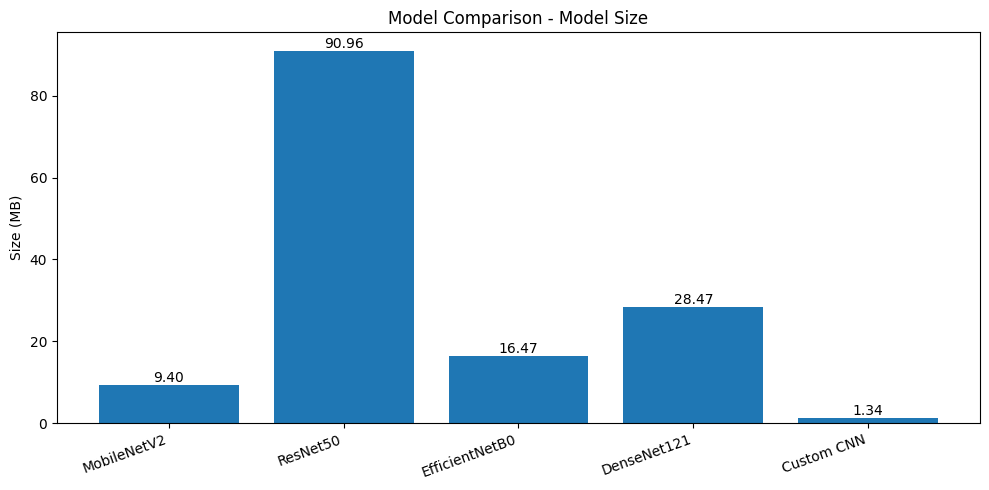

Saved: /content/drive/MyDrive/DL-2 Project/comparison_charts/model_size_comparison.png

All four comparison charts generated successfully!


In [18]:

import os
import json
import matplotlib.pyplot as plt

# Paths to saved metrics
model_files = {
    "MobileNetV2": "mobilenetv2_metrics.json",
    "ResNet50": "resnet50_metrics.json",
    "EfficientNetB0": "efficientnetb0_metrics.json",
    "DenseNet121": "densenet121_metrics.json",
    "Custom CNN": "custom_cnn_metrics.json"
}

# Checkpoint filenames
checkpoint_files = {
    "MobileNetV2": "mobilenetv2_best.keras",
    "ResNet50": "resnet50_best.keras",
    "EfficientNetB0": "efficientnetb0_best.keras",
    "DenseNet121": "densenet121_best.keras",
    "Custom CNN": "custom_cnn_best.keras"
}

# Load metrics and normalize their different key formats
model_metrics = {}

for name, filename in model_files.items():
    path = os.path.join(PROJECT_DIR, filename)

    with open(path, "r") as f:
        raw = json.load(f)

    # Support both naming formats in your existing files
    model_metrics[name] = {
        "accuracy": raw.get("Test Accuracy", raw.get("accuracy")),
        "macro_f1": raw.get("Macro F1", raw.get("macro_f1")),
        "training_time": raw.get(
            "Training Time (min)", raw.get("training_time_minutes")
        )
    }

    # Get model size from its actual checkpoint
    checkpoint_path = os.path.join(
        MODEL_DIR, checkpoint_files[name]
    )

    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    model_metrics[name]["model_size"] = (
        os.path.getsize(checkpoint_path) / (1024 * 1024)
    )

# Validate required metrics
for name, metrics in model_metrics.items():
    for key, value in metrics.items():
        if value is None:
            raise ValueError(f"Missing {key} for {name}")

# Prepare output folder
chart_dir = os.path.join(PROJECT_DIR, "comparison_charts")
os.makedirs(chart_dir, exist_ok=True)

# Metric, title, axis label, multiplier
charts = [
    ("accuracy", "Test Accuracy", "Accuracy (%)", 100),
    ("macro_f1", "Macro F1-Score", "Macro F1 (%)", 100),
    ("training_time", "Training Time", "Minutes", 1),
    ("model_size", "Model Size", "Size (MB)", 1)
]

model_names = list(model_metrics.keys())

for metric, title, ylabel, multiplier in charts:
    values = [
        model_metrics[name][metric] * multiplier
        for name in model_names
    ]

    plt.figure(figsize=(10, 5))
    bars = plt.bar(model_names, values)

    plt.title(f"Model Comparison - {title}")
    plt.ylabel(ylabel)
    plt.xticks(rotation=20, ha="right")
    plt.bar_label(bars, fmt="%.2f")
    plt.tight_layout()

    filename = f"{metric}_comparison.png"
    output_path = os.path.join(chart_dir, filename)

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", output_path)

print("\nAll four comparison charts generated successfully!")

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

project_path = "/content/drive/MyDrive/DL-2 Project"

print("Project folder exists:", os.path.exists(project_path))
print("\nFiles and folders:")
print(os.listdir(project_path))

Project folder exists: True

Files and folders:
['Animal_Classification_Project_v2.ipynb', 'Animal_Classification_Project.ipynb', 'saved_models', 'mobilenetv2_metrics.json', 'resnet50_metrics.json', 'efficientnetb0_metrics.json', 'densenet121_metrics.json', 'custom_cnn_metrics.json', 'efficientnetb0_confusion_matrix.png', 'comparison_charts']


In [6]:
import json
import os

project_path = "/content/drive/MyDrive/DL-2 Project"

for filename in os.listdir(project_path):
    if filename.endswith(".ipynb"):
        print("Notebook:", filename)

print("\nSaved model files:")
print(os.listdir(os.path.join(project_path, "saved_models")))

Notebook: Animal_Classification_Project_v2.ipynb
Notebook: Animal_Classification_Project.ipynb

Saved model files:
['mobilenetv2_best.keras', 'resnet50_best.keras', 'efficientnetb0_best.keras', 'densenet121_best.keras', 'custom_cnn_best.keras']


In [7]:

import json
import os

notebook_path = "/content/drive/MyDrive/DL-2 Project/Animal_Classification_Project_v2.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if any(term in source.lower() for term in [
        "image_dataset_from_directory",
        "class_names",
        "flow_from_directory"
    ]):
        print(f"\n--- CELL {i} ---")
        print(source[:2500])



--- CELL 2 ---

import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(DATASET_DIR, "train")
val_dir = os.path.join(DATASET_DIR, "validation")
test_dir = os.path.join(DATASET_DIR, "test")

# Training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

class_names = train_ds.class_names

# Validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE

In [8]:

import os

print("Dataset directory variable exists:", "DATASET_DIR" in globals())


Dataset directory variable exists: False


In [10]:
import json

path = "/content/drive/MyDrive/DL-2 Project/Animal_Classification_Project_v2.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"][:3]):
    print(f"\n--- CELL {i} ---")
    print("".join(cell.get("source", [])))


--- CELL 0 ---
from google.colab import drive
import os
import tensorflow as tf

# Mount Google Drive
drive.mount("/content/drive")

# Permanent project locations
PROJECT_DIR = "/content/drive/MyDrive/DL-2 Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "saved_models")

# Create model storage folder if needed
os.makedirs(MODEL_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("Project folder exists:", os.path.isdir(PROJECT_DIR))
print("Model storage folder:", MODEL_DIR)
print("Model storage ready:", os.path.isdir(MODEL_DIR))

--- CELL 1 ---

import os
import sys
import subprocess

# Install KaggleHub if it isn't available in this runtime
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "kagglehub"
])

import kagglehub

print("Restoring the animal dataset...")

dataset_path = kagglehub.dataset_download(
    "mkstar1/animal-dataset-with-15-classes-of-animals"
)

DATASET_DI

In [12]:
import os
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/DL-2 Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "saved_models")
DATASET_DIR = "/kaggle/input/animal-dataset-with-15-classes-of-animals/Dataset"

print("Dataset exists:", os.path.isdir(DATASET_DIR))
print("Models folder exists:", os.path.isdir(MODEL_DIR))
print(
    "EfficientNetB0 exists:",
    os.path.isfile(os.path.join(MODEL_DIR, "efficientnetb0_best.keras"))
)

Dataset exists: True
Models folder exists: True
EfficientNetB0 exists: True


In [13]:
train_dir = os.path.join(DATASET_DIR, "train")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("\nEXACT CLASS ORDER:")
print(train_ds.class_names)

Found 7262 files belonging to 15 classes.

EXACT CLASS ORDER:
['Armadilles', 'Bear', 'Birds', 'Cow', 'Crocodile', 'Deer', 'Elephant', 'Goat', 'Horse', 'Jaguar', 'Monkey', 'Rabbit', 'Skunk', 'Tiger', 'Wild Boar']


In [16]:
import os

print(os.listdir("/content"))

['.config', 'Lion Image.jpeg', 'drive', 'sample_data']


In [18]:

import numpy as np
from PIL import Image
from tensorflow import keras

MODEL_PATH = "/content/drive/MyDrive/DL-2 Project/saved_models/efficientnetb0_best.keras"
IMAGE_PATH = "/content/Lion Image.jpeg"

model = keras.models.load_model(MODEL_PATH)

image = Image.open(IMAGE_PATH).convert("RGB").resize((224, 224))
image_array = np.asarray(image, dtype=np.float32)[None, ...]

probabilities = model.predict(image_array, verbose=0)[0]
top_indices = np.argsort(probabilities)[-3:][::-1]

class_names = [
    "Armadilles", "Bear", "Birds", "Cow", "Crocodile",
    "Deer", "Elephant", "Goat", "Horse", "Jaguar",
    "Monkey", "Rabbit", "Skunk", "Tiger", "Wild Boar"
]

for index in top_indices:
    print(f"{class_names[index]}: {probabilities[index]:.2%}")
for index in top_indices:
    print(f"{class_names[index]}: {probabilities[index]:.2%}")

Horse: 31.10%
Monkey: 21.28%
Tiger: 18.23%
Horse: 31.10%
Monkey: 21.28%
Tiger: 18.23%


In [19]:

import os
import numpy as np
from PIL import Image

horse_dir = os.path.join(DATASET_DIR, "test", "Horse")
horse_files = [
    f for f in os.listdir(horse_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Horse test images found:", len(horse_files))
print("Example filename:", horse_files[0] if horse_files else "None")


Horse test images found: 105
Example filename: 0733.jpg


In [20]:
horse_path = os.path.join(horse_dir, horse_files[0])

image = Image.open(horse_path).convert("RGB").resize((224, 224))
image_array = np.asarray(image, dtype=np.float32)[None, ...]

probabilities = model.predict(image_array, verbose=0)[0]
top_indices = np.argsort(probabilities)[-3:][::-1]

for index in top_indices:
    print(f"{class_names[index]}: {probabilities[index]:.2%}")

Horse: 92.59%
Elephant: 6.67%
Cow: 0.51%


In [21]:

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix

PROJECT_DIR = "/content/drive/MyDrive/DL-2 Project"
MODEL_PATH = os.path.join(
    PROJECT_DIR, "saved_models", "efficientnetb0_best.keras"
)

DATASET_DIR = (
    "/kaggle/input/animal-dataset-with-15-classes-of-animals/Dataset"
)

class_names = [
    "Armadilles", "Bear", "Birds", "Cow", "Crocodile",
    "Deer", "Elephant", "Goat", "Horse", "Jaguar",
    "Monkey", "Rabbit", "Skunk", "Tiger", "Wild Boar"
]

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    class_names=class_names,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

model = keras.models.load_model(MODEL_PATH)

y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print("\nTEST ACCURACY:", f"{np.mean(y_true == y_pred):.2%}")
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)
print("\nMOST FREQUENT CLASS CONFUSIONS:")
for i in range(len(class_names)):
    row = cm[i].copy()
    row[i] = 0
    j = int(np.argmax(row))
    if row[j] > 0:
        print(f"{class_names[i]} predicted as {class_names[j]}: {row[j]} images")


Found 899 files belonging to 15 classes.
29/29 ━━━━━━━━━━━━━━━━━━━━ 25s 444ms/step

TEST ACCURACY: 97.55%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Armadilles     0.9915    0.9831    0.9872       118
        Bear     1.0000    0.9804    0.9901        51
       Birds     0.9583    1.0000    0.9787        23
         Cow     1.0000    1.0000    1.0000        39
   Crocodile     1.0000    1.0000    1.0000        25
        Deer     0.9722    0.9722    0.9722        72
    Elephant     0.9744    0.9620    0.9682        79
        Goat     0.9062    1.0000    0.9508        29
       Horse     0.9528    0.9619    0.9573       105
      Jaguar     1.0000    1.0000    1.0000        88
      Monkey     1.0000    1.0000    1.0000        28
      Rabbit     0.9610    0.9610    0.9610        77
       Skunk     0.9836    0.9375    0.9600        64
       Tiger     1.0000    1.0000    1.0000        43
   Wild Boar     0.9322    0.9483    0.9402        58

    